## Reto: Mi primer Transformer Variacional

Valentina Pérez Cadavid

 # Definir planteamiento del sistema y parámetros iniciales 

Consideremos una red cuadrada de LxL sitios, con $N=L^{2}$ espines $s_{i}$ $\in \{ +1,-1 \}$ y condiciones de frontera periódicas.
Para este sistema, la energía de una configuración está dada por:

$$E(s)= -J\sum_{\left\langle i,j \right\rangle}^{}s_{i}s_{j}-h_{campo}\sum_{i}^{}s_{i}$$


Además, a nivel computacional se tienen en cuanta las siguientes consideraciones con respecto a las posibles variables que controlan el desempeño del modelo:
| Fuente de error | Pregunta | Qué la controla |
|---|---|---|
| **1. Capacidad** | ¿La red **puede** representar a Boltzmann, aunque sea en principio? | $d$, número de capas, número de cabezas |
| **2. Entrenamiento** | ¿Entrenó **lo suficiente** para llegar cerca de su mejor versión? | $K$ (iteraciones), $\eta$ (tasa de aprendizaje) |
| **3. Ruido estadístico** | ¿Las **mediciones** con el lote son precisas? | $M$ (tamaño del lote) |



Para esto se definen las siguientes consideraciones:
1. Creación de la red con $L=3$, $h_{campo}=0$ y $J=1$
2. Establecer parámetros de entrenamiento:
    - Tamaño de lote = 256
    - Número de iteraciones = 2000
    - Tasa de aprendizaje $\eta=1\cdot 10^{-3}$
3. Definir el tamaño del Transformer:
    - Tamaño del vector $d$ de tokens = 32
    - Número de cabezas de atención = 1






In [9]:
import torch                       # tensores + derivación automática (backward)
import torch.nn as nn              # bloques para construir redes (capas, embeddings)
import torch.nn.functional as F_nn # funciones como log_softmax
                                   # (F_nn para no confundirlo con la energía libre F)
import numpy as np
import matplotlib.pyplot as plt
import math    

In [ ]:
# Fijar Semilla
torch.manual_seed(0)
np.random.seed(0)

# Si hay GPU la usa; si no, CPU. Pero para L = 3 la CPU es suficiente.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# 1. Creación de la red de espines

L = 3            
N = L * L        
J = 1.0          
h_campo = 0.0    
T = 2.0          

# 2. Establecer parámetros del entrenamiento

M = 256          # tamaño del lote: # configuraciones generadas por iteración
K = 2000         # número de iteraciones 
eta = 1e-3       # tasa de aprendizaje de Adam


# 3. Establecer el tamaño del Transformer

d_model = 32     # d: tamaño del vector de cada token

# 4. Tokens 

TOKEN_MENOS = 0  # espín -1  -> token 0
TOKEN_MAS   = 1  # espín +1  -> token 1
TOKEN_BOS   = 2  # token de inicio de secuencia
VOCAB       = 3  # cuántos tokens distintos existen


print(f"Dispositivo: {device}")
print(f"Red {L}x{L} -> N = {N} espines, {2**N} configuraciones posibles")
print(f"T = {T}, J = {J}, h = {h_campo}")
print(f"Lote M = {M}, iteraciones K = {K}, eta = {eta}")

Dispositivo: cpu
Red 3x3 -> N = 9 espines, 512 configuraciones posibles
T = 2.0, J = 1.0, h = 0.0
Lote M = 256, iteraciones K = 2000, eta = 0.001


# Representación por Tokens

En este paso, sobre la red de espines se debe:
1. Recibir la red de espines como una secuencia de 1 y -1.
2. Transformar cada espín en su representación como token: se define un token de inicio de secuencia (BOS):

| Valor | Token |
|---|---|
| $-1$ | 0 |
| $+1$ | 1 |
| BOS | 2 |

3. Construir la entrada desplazada agregando el token BOS al inicio.

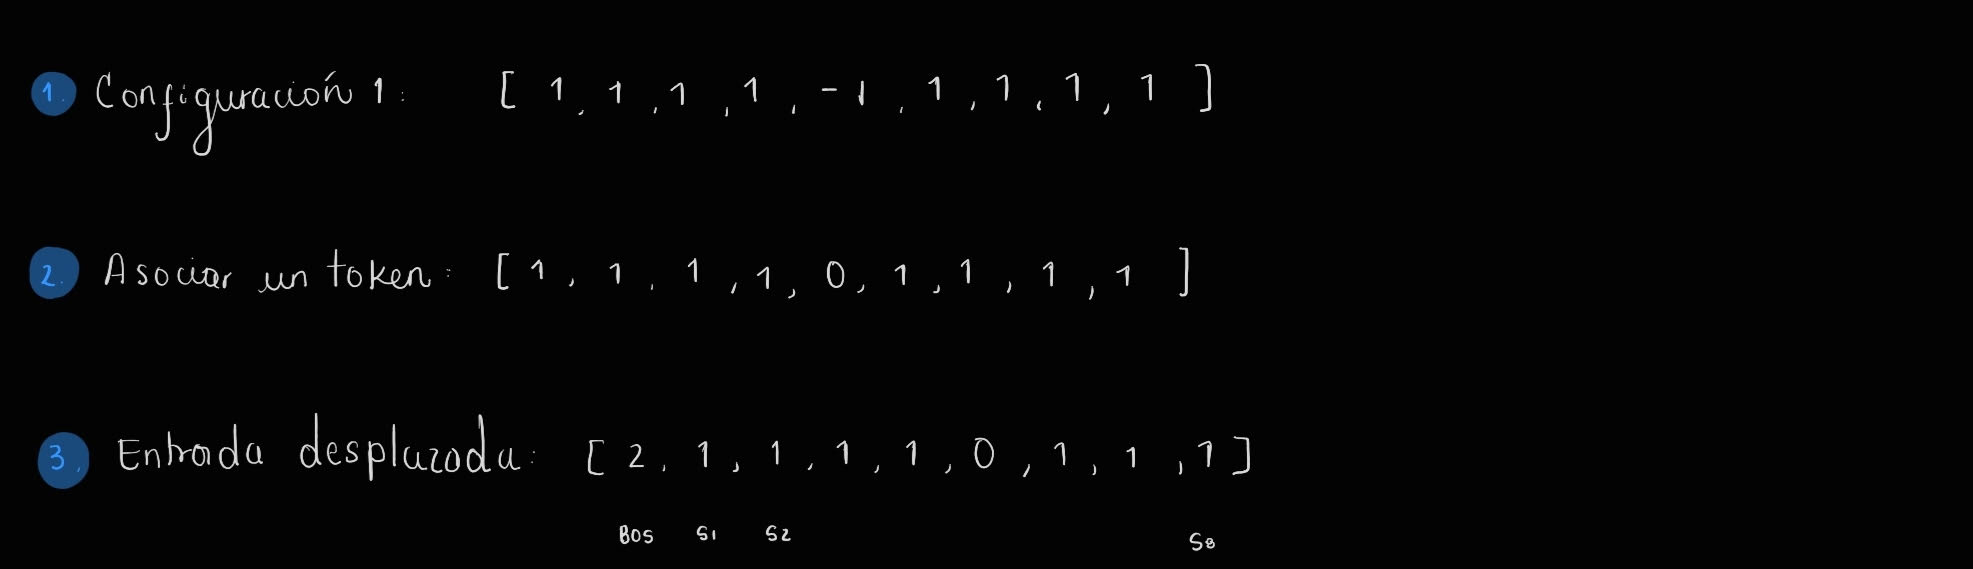

In [16]:

# 2. Tokens y entradas desplazadas.
def espines_a_tokens(s):
    """
    Convierte espines ±1 en tokens 0/1.
    Entrada:  s, tensor de forma (M(# de configuraciones), N(# de espines de la red)) con valores -1 y +1
    Salida:   tensor de forma (M, N) con valores 0 y 1
    """
    return ((s + 1) // 2).long()   # .long() convierte a enteros.

# 3. Entrada desplazada
def entrada_desplazada(s):
    """
    Arma la entrada del Transformer: [BOS, s1, ..., s_{N-1}].
    Entrada:  s, tensor (M, N) de espines ±1  (la configuración completa)
    Salida:   tensor (M, N) de tokens, empezando con BOS y sin el último espín
    La posición i de la entrada contiene s_{i-1}, así el Transformer
    nunca ve el espín que tiene que predecir.
    """
    M_lote = s.shape[0]                        # cuántas configuraciones vienen
    tokens = espines_a_tokens(s)               # (M, N) con 0/1

    # Una columna llena de BOS, una por configuración: forma (M, 1)
    bos = torch.full((M_lote, 1), TOKEN_BOS, dtype=torch.long, device=s.device)

    # Se pega el BOS al inicio y quitamos el último token:
    # tokens[:, :-1] = todas las filas, todas las columnas menos la última
    return torch.cat([bos, tokens[:, :-1]], dim=1)   # dim=1: pegar como columnas




In [8]:
# Prueba con 2 configuraciones
# ---------------------------------------------------------------------
s_ejemplo = torch.tensor([[ 1,  1,  1,  1, -1,  1,  1,  1,  1],
                          [ 1,  1,  1,  1,  1,  1,  1,  1,  1]], device=device)

print("Espines:\n", s_ejemplo)
print("Tokens:\n", espines_a_tokens(s_ejemplo))
print("Entrada desplazada:\n", entrada_desplazada(s_ejemplo))
print("Forma:", entrada_desplazada(s_ejemplo).shape)

Espines:
 tensor([[ 1,  1,  1,  1, -1,  1,  1,  1,  1],
        [ 1,  1,  1,  1,  1,  1,  1,  1,  1]])
Tokens:
 tensor([[1, 1, 1, 1, 0, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1]])
Entrada desplazada:
 tensor([[2, 1, 1, 1, 1, 0, 1, 1, 1],
        [2, 1, 1, 1, 1, 1, 1, 1, 1]])
Forma: torch.Size([2, 9])


# Estructurar el Transformer

Luego de haber configurado la forma del sistema, se procede a realizar algunos de los procesos que realiza el Transformer:

4. Embedding de token.

5. Embedding de posiciones.

6. Mezclar ambos embeddings.

7. Armar la capa de atención.

Estos se decriben en las siguientes notas.

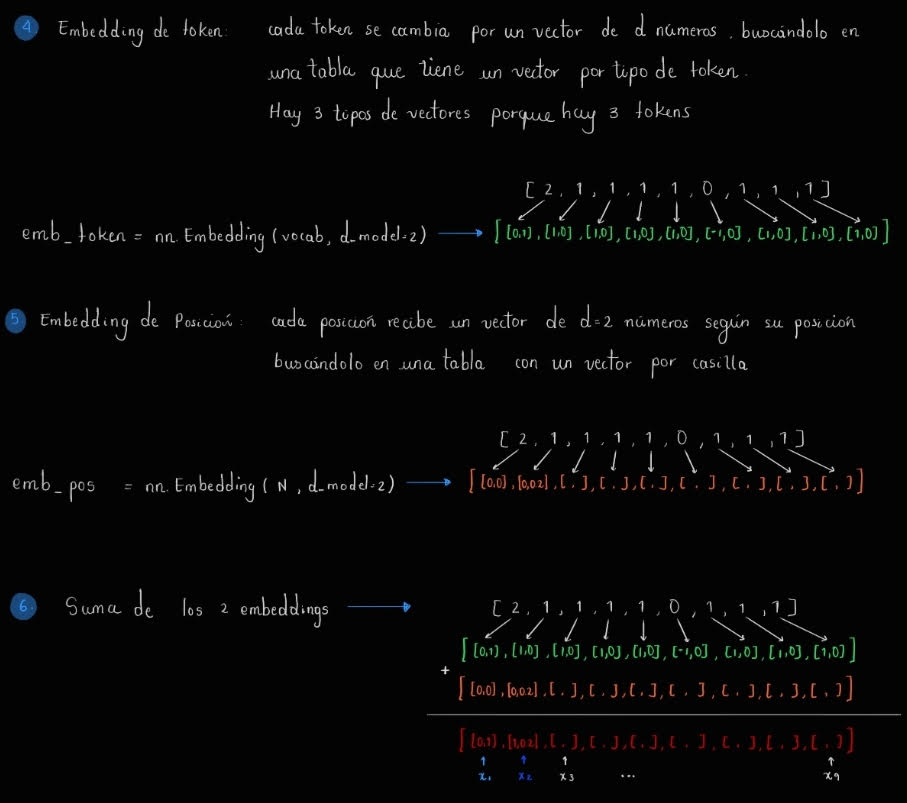
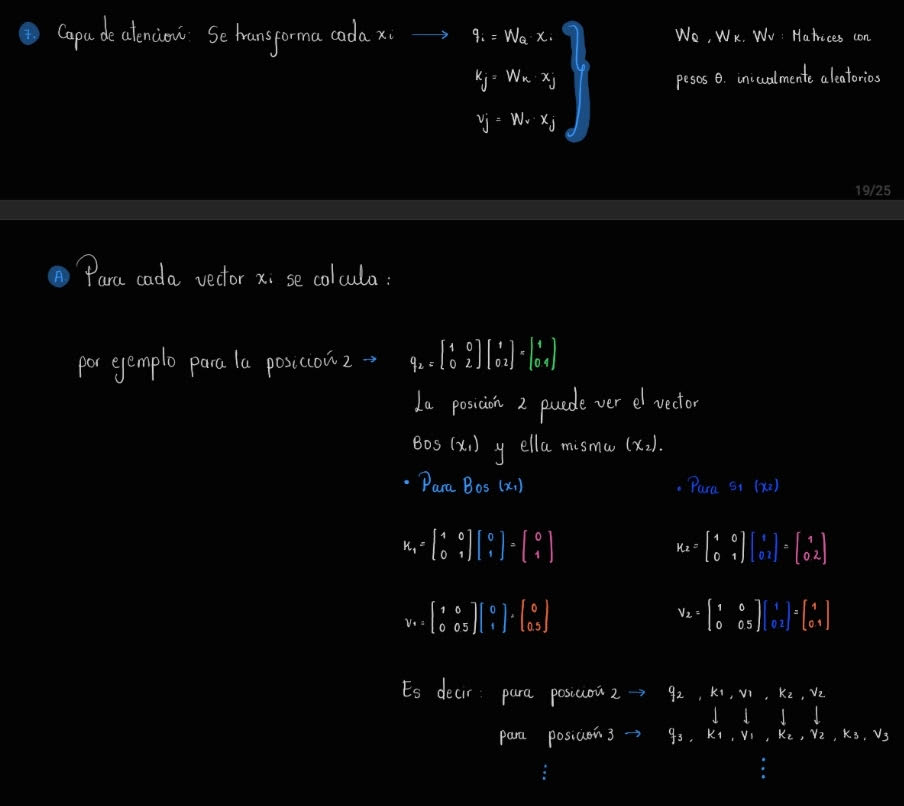\
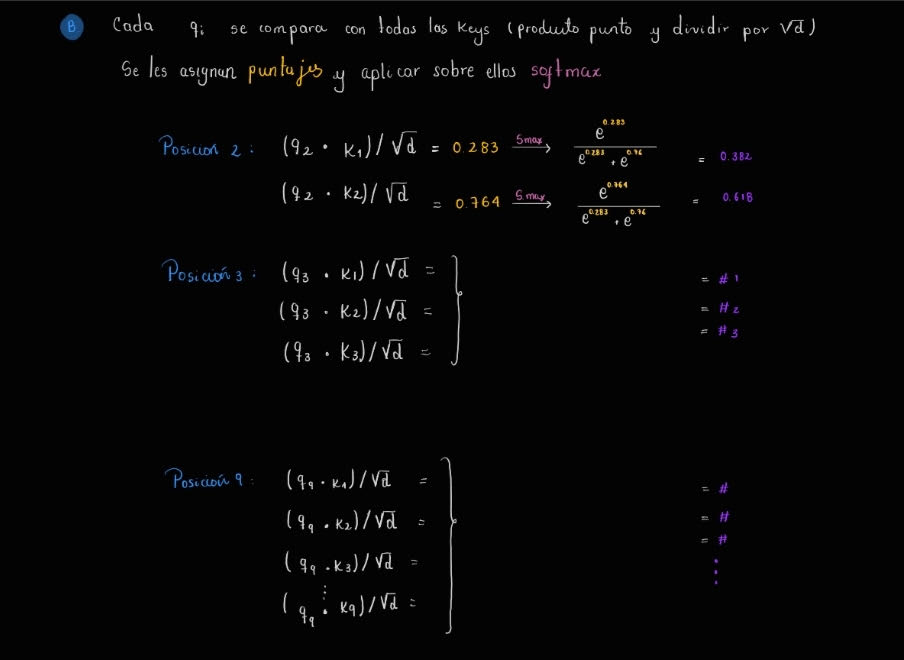
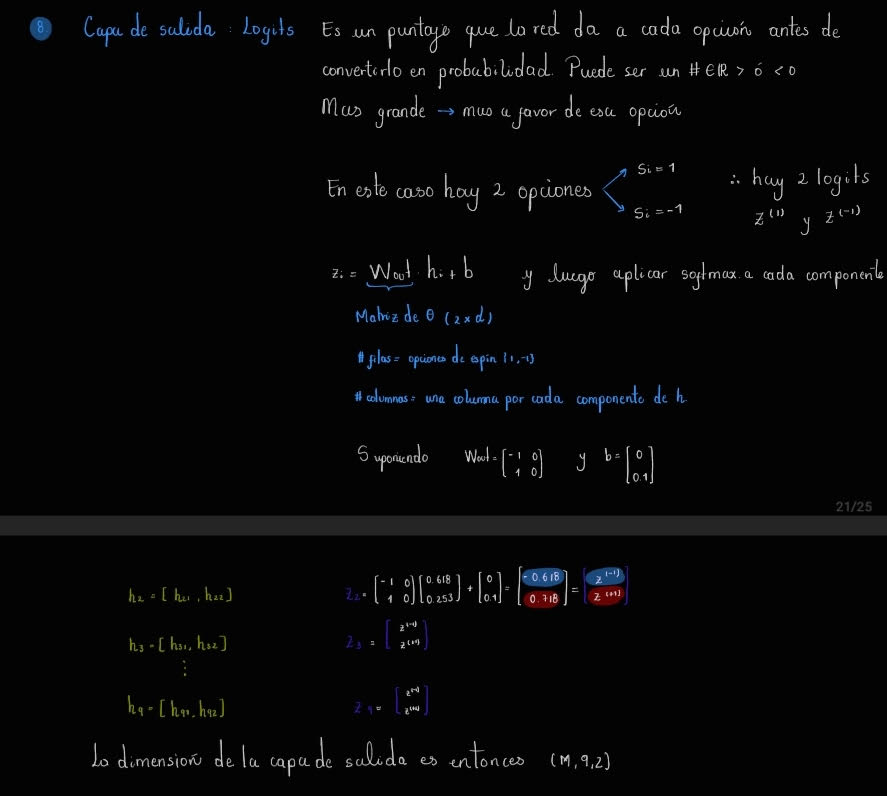



In [ ]:
# TRANSFORMER  (numerado según las notas a mano)

class Transformer(nn.Module):
    def __init__(self, N, d_model, vocab=VOCAB):
        super().__init__()
        self.d = d_model   # tamaño de cada vector (d = 32)

    
        # 4. Tabla 3 x d. Un vector de d componentes por cada tipo de token (0, 1, BOS)
        self.emb_token = nn.Embedding(vocab, d_model)
        # 5. Tabla N x d. Un vector de d componentes por cada posición (0, 1, ..., 8)
        self.emb_pos   = nn.Embedding(N, d_model)

        # 7. Crear la capa de atención (1 capa, 1 cabeza)
        
        # nn.Linear(tamaño de entrada, tamaño de salida, bias=False) = solo "W · x", sin "+ b"
        self.W_Q = nn.Linear(d_model, d_model, bias=False)
        self.W_K = nn.Linear(d_model, d_model, bias=False)
        self.W_V = nn.Linear(d_model, d_model, bias=False)

        # 7B. crear la máscara causal (N x N)
        # True = prohibido (casillas del futuro, arriba de la diagonal).
        # register_buffer: se guarda en el modelo, pero NO es un parámetro (Adam no la toca).
        mascara = torch.triu(torch.ones(N, N, dtype=torch.bool), diagonal=1)
        self.register_buffer("mascara", mascara)

        # 8. Crear la capa de salida:  z = W_out · h + b 
        # nn.Linear(entra h de d componentes, salen 2 logits z^(-1) y z^(+1), con "+ b")
        # W_out: 2 x d
        self.capa_salida = nn.Linear(d_model, 2, bias=True)

    def forward(self, tokens):
        n = tokens.shape[1]
        pos = torch.arange(n, device=tokens.device)    # números de casilla: [0, 1, ..., n-1]

        # ---- Pasos 4, 5 y 6: embeddings ----
        # Paso 4: emb_token(tokens) -> busca el vector de cada token       (M, n, d)
        # Paso 5: emb_pos(pos)      -> busca el vector de cada casilla      (n, d)
        # Paso 6: se suman          -> x_i = e(token_i) + p_i               (M, n, d)
        x = self.emb_token(tokens) + self.emb_pos(pos)

        # ---- Paso 7: capa de atención ----
        # 7A) Calcular q_i, k_i, v_i para cada vector x_i (todas las casillas a la vez) cada uno con forma (M, n, d)
        q = self.W_Q(x)
        k = self.W_K(x)
        v = self.W_V(x)

        # 7B) Comparar cada q_i con todas las k_j (producto punto) y dividir por √d
        #     q @ k^T -> matriz (M, n, n): la fila i tiene los puntajes de la posición i
        puntajes = q @ k.transpose(1, 2) / math.sqrt(self.d)

        # Máscara causal: los puntajes del futuro se vuelven -∞ (su peso será e^(-∞) = 0)
        puntajes = puntajes.masked_fill(self.mascara[:n, :n], float('-inf'))

        # Softmax sobre los puntajes de cada fila -> pesos que suman 1    (M, n, n)
        pesos = torch.softmax(puntajes, dim=-1)

        # 7C) Calcular los h_i
        #     h_i = Σ_j w_ij · v_j   (la posición i suma i términos)         (M, n, d)
        h = pesos @ v

        # 8: capa de salida -> logits 
        # z_i = W_out · h_i + b    (la softmax NO va aquí: se aplica después, en log_prob)
        return self.capa_salida(h)                                           # (M, n, 2)

# Pasar de logits a probabilidades
Luego de la capa de salida del Transformer, se procede a aplicar el softmax sobre cada uno de los logits y obtener su logaritmo.
Este proceso se detalla en las siguientes notas:


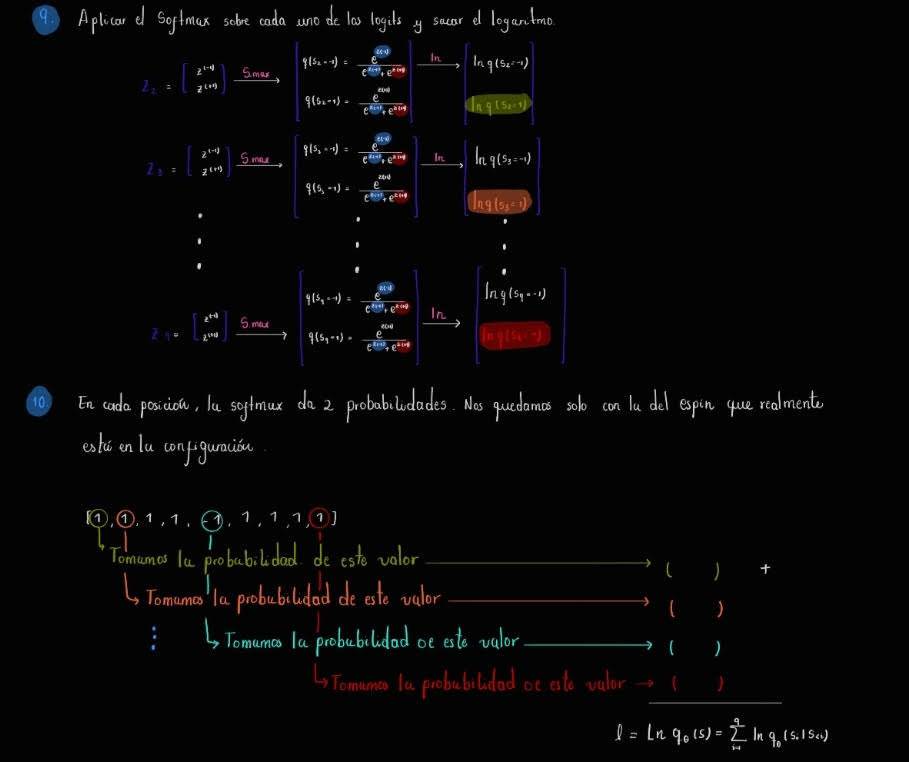

In [ ]:
# PARTE 2: log_prob  ->  ℓ = ln q_θ(s)   (pasos 9 y 10 )
def log_prob(modelo, s):
    """
    Entrada:  s, configuraciones de espines ±1, forma (M, N)
    Salida:   ell de cada configuración, forma (M,)
              logp_real, el ln q de cada posición, forma (M, N)  (útil para revisar)
    """
    # Tokens y entrada desplazada [BOS, s1, ..., s_{N-1}]  -> (M, N)
    entrada = entrada_desplazada(s)

    # Aplicar el modelo para conseguir los logits                         -> (M, N, 2)
    logits = modelo(entrada)

    # Paso 9: log-softmax sobre los 2 logits de cada posición             -> (M, N, 2)
    #   logp[..., 0] = ln q(s_i = -1 | s_<i)
    #   logp[..., 1] = ln q(s_i = +1 | s_<i)
    logp = F_nn.log_softmax(logits, dim=-1) # # Dado que logits es de dimensión (M,N,2), se debe aplicar el softmax en la última dimensión (dim=-1) , la cual es la de tamaño 2.

    # Paso 10: escoger, en cada posición, el ln q del espín REAL           -> (M, N)
    # s       = [ +1,   +1,   +1,   +1,   -1,    +1,   +1,   +1,   +1  ]
    # s == 1  = [True, True, True, True, False, True, True, True, True ]  
    # logp[..., 1] tomar la columna 1 de la ultima dimensión (espín +1) donde s == 1
    # logp[..., 0] tomar la columna 0 de la ultima dimensión (espín -1) donde s == -1
    
    logp_real = torch.where(s == 1, logp[..., 1], logp[..., 0])

    # Paso 11: sumar las N posiciones -> ℓ de cada configuración           -> (M,)
    ell = logp_real.sum(dim=1)

    return ell, logp_real

# Calculo de la energía de Ising de cada configuración

Ahora, se calcula la energía de Ising considerando $J=1$ y $h=0$:
$$E(s)= -J\sum_{\left\langle i,j \right\rangle}^{}s_{i}s_{j}-h_{campo}\sum_{i}^{}s_{i}$$
$$E(s)=-\sum_{\left\langle i,j \right\rangle}^{}s_{ij}(s_{i,j+1} + s_{i+1,j})$$

In [22]:
def energia_ising(s, L=L, J=J, h_campo=h_campo):
   
    M_lote = s.shape[0]
    red = s.reshape(M_lote, L, L).float()        # volver a armar la red L x L
    E = torch.zeros(M_lote, device=s.device)

    for m in range(M_lote):                      # cada configuración del lote
        suma_enlaces = 0.0
        suma_espines = 0.0
        for i in range(L):                       # filas
            for j in range(L):                   # columnas
                s_ij    = red[m, i, j]                 # el espín de esta casilla
                derecha = red[m, i, (j + 1) % L]       # s_{i, j+1}  (módulo L para frontera periódica)
                abajo   = red[m, (i + 1) % L, j]       # s_{i+1, j}  (módulo L para frontera periódica)
                suma_enlaces += s_ij * (derecha + abajo)
                suma_espines += s_ij
        E[m] = -J * suma_enlaces - h_campo * suma_espines

    return E # Devuelve un vector que contiene la energía de cada configuración.

# Calculo de la energía libre $f_{m}$



Para cada configuración $\mathbf{s}^{(m)}$ del lote ($m = 1, \dots, M$) ya se conocen entonces:

- su energía de Ising, $E_m = E(\mathbf{s}^{(m)})$, y
- su log-probabilidad bajo el modelo, $\ell_m = \ln q_\theta(\mathbf{s}^{(m)})$.

Con ellas se define, para cada configuración,

$$f_m = E_m + T\,\ell_m ,$$


Promediando luego sobre el lote se obtienen los estimadores de la energía libre, la energía media y la entropía:

$$\widehat{F}_\theta = \frac{1}{M}\sum_{m=1}^{M} f_m, \qquad
\widehat{U}_\theta = \frac{1}{M}\sum_{m=1}^{M} E_m, \qquad
\widehat{S}_\theta = -\frac{1}{M}\sum_{m=1}^{M} \ell_m .$$

Estas cantidades satisfacen

$$\widehat{F}_\theta = \widehat{U}_\theta - T\,\widehat{S}_\theta ,$$

lo cual sirve como verificación del cálculo.

Luego, en cada iteración se registrarán $\widehat{F}_\theta$, $\widehat{U}_\theta$ y $\widehat{S}_\theta$ para construir las curvas de entrenamiento.

In [23]:
def estimar_energia_libre_del_Lote(E, ell, T=T):

    
    f = E + T * ell # Vector que contiene la energía libre de cada configuración.

    # Promedios del lote (.mean() = sumar y dividir por M)
    F_hat = f.mean()            # energía libre estimada
    U_hat = E.mean()            # energía media
    S_hat = -ell.mean()         # entropía estimada (ojo con el signo menos)

    return f, F_hat, U_hat, S_hat

# Función Auxiliar $L_{aux}$
Una vez definidos los promedios, se define la función auxiliar 
$$L_{aux}=\frac{1}{M}\sum_{m}^{M} stopgrad(f_{m}-\widehat{F})l_{m}$$

In [26]:
def funcion_auxiliar(f, ell):
    F_hat = f.mean()                 # F̂ = promedio de f_m en el lote
    c = f - F_hat                    # c_m = f_m − F̂   (cuánto se aleja cada configuración)
    c = c.detach()                   # stopgrad: c se trata como número fijo, no se deriva
    producto = c * ell               # c_m · ℓ_m   para cada configuración
    L_aux = producto.mean()          # (1/M) Σ_m c_m · ℓ_m
    return L_aux

# Generación de un lote de configuraciones (muestreo)

En cada iteración se generan $M$ configuraciones independientes $\mathbf{s}^{(1)}, \dots, \mathbf{s}^{(M)} \sim q_\theta$ usando los parámetros actuales del Transformer.

Cada configuración se construye **espín por espín**, siguiendo la factorización autoregresiva:

1. Se comienza con el token BOS.
2. En la posición $i$, el Transformer recibe los espines ya generados $s_{<i}$ y calcula la probabilidad condicional del siguiente espín, $q_\theta(s_i \mid s_{<i})$.
3. Se sortea $s_i \in \{-1, +1\}$ de acuerdo con esa probabilidad.
4. El espín obtenido se añade a la secuencia de entrada y se pasa a la posición $i+1$.

Cabe aclarar que el Transformer no fija el valor de cada espín, solo determina su probabilidad. El valor se obtiene por sorteo, de modo que cada configuración aparece con frecuencia $q_\theta(\mathbf{s}) = \prod_{i=1}^{N} q_\theta(s_i \mid s_{<i})$. El entrenamiento ajusta los parámetros $\theta$ para que estas frecuencias se aproximen a las de la distribución de Boltzmann.



In [ ]:
@torch.no_grad()                                   
def muestrear(modelo, M_lote, N=N):
    
    entrada = torch.full((M_lote, 1), TOKEN_BOS, dtype=torch.long, device=device)  # Crea un tensor de tamaño Mx1, donde el primer token de cada configuración es el token del BOS.
    espines = torch.zeros(M_lote, N, dtype=torch.long, device=device)

    for i in range(N):                             # ← Bloque 3 (el ciclo)
        logits = modelo(entrada)
        probs = torch.softmax(logits[:, -1, :], dim=-1) # dim=-1: especifica en qué dirección se aplica el softmax sobre los 2 logits.
        token = torch.multinomial(probs, num_samples=1) # genera M tokens (0 o 1), uno por configuración, para la posición i
        espines[:, i] = 2 * token[:, 0] - 1 # Se convierte el token (0/1) en espín (-1/+1)
        entrada = torch.cat([entrada, token], dim=1)

    return espines

# Inicialización del Entrenamiento


### Número de parámetros del modelo

El número de parámetros entrenables $\theta$ del modelo está determinado únicamente por la **arquitectura**, es decir, por las dimensiones de las matrices que lo componen, y **no** por los hiperparámetros del entrenamiento (número de iteraciones $K$, tamaño del lote $M$, tasa de aprendizaje $\eta$ o temperatura $T$).

Para el Transformer de una capa de atención implementado, con dimensión de embedding $d$, vocabulario de 3 tokens ($-1$, $+1$ y BOS) y $N = L^2$ posiciones, el número total de parámetros es:

$$
n_{\theta} = \underbrace{3d}_{\text{emb. de token}} + \underbrace{N d}_{\text{emb. de posición}} + \underbrace{3d^{2}}_{W_Q,\, W_K,\, W_V} + \underbrace{2d + 2}_{\text{capa de salida}}
$$

Para $L = 3$ ($N = 9$) y $d = 32$:

$$
n_{\theta} = 96 + 288 + 3072 + 66 = 3522
$$

El término dominante es $3d^{2}$, asociado a las matrices de consulta, clave y valor de la atención, por lo que duplicar $d$ incrementa el número de parámetros.

In [ ]:
torch.manual_seed(0)                     

modelo = Transformer(N, d_model).to(device)
# Crea el Transformer: emb_token, emb_pos, W_Q, W_K, W_V, capa_salida, se llenan con parámetros aleatorios pequeños.


optimizador = torch.optim.Adam(modelo.parameters(), lr=eta)
# Adam: la herramienta que moverá los parámetros en la dirección que baja F.
# modelo.parameters() -> le entrega la lista de todos los parámetros que puede modificar


n_param = sum(p.numel() for p in modelo.parameters())
print(f"Número de parámetros θ: {n_param}")   # El número de parámetros depende de d=2

Número de parámetros θ: 3522


## Loop de Entrenamiento
En este puento, se repite para cada una de las $K=2000$ iteraciones:
- Generar lote
- Evaluar
- Estimar F
- Ajustar parámetros

In [ ]:
# Para cada iteración se guardan los valores de F̂, Û y Ŝ para graficar luego.
historial_F = []      
historial_U = []
historial_S = []

for k in range(K):                                   
    # Generar M configuraciones de ±1 (M, N): 
    s = muestrear(modelo, M)                          

    # PASO 4. Evaluar E y ell 
    E = energia_ising(s)                             # (M,): energía de cada configuración
    ell, _ = log_prob(modelo, s)                     # (M,): ell = ln q(s_m), con gradientes

    # PASO 5. estimar F̂, Û, Ŝ  
    f, F_hat, U_hat, S_hat = estimar_energia_libre_del_Lote(E, ell)

    # PASO 6. Construir L_aux
    L_aux = funcion_auxiliar(f, ell)

    # PASO 7. Actualizar θ 
    optimizador.zero_grad()      # borra los gradientes de la iteración anterior
    L_aux.backward()             # calcula ∂L_aux/∂θ para los 3522 parámetros
    optimizador.step()           # Adam mueve cada θ un pasito

    # Guardar valores en la lista
    historial_F.append(F_hat.item())                 # .item() → convierte el tensor en número normal
    historial_U.append(U_hat.item())
    historial_S.append(S_hat.item())

    if k % 200 == 0:                                 # imprime cada 200 iteraciones
        print(f"k={k:4d}   F̂={F_hat.item():8.3f}   Û={U_hat.item():8.3f}   Ŝ={S_hat.item():6.3f}")
        
    # Fin del entrenamiento.

k=   0   F̂= -12.621   Û=  -0.156   Ŝ= 6.233
k= 200   F̂= -19.822   Û= -15.922   Ŝ= 1.950
k= 400   F̂= -19.838   Û= -16.109   Ŝ= 1.864
k= 600   F̂= -19.861   Û= -15.859   Ŝ= 2.001
k= 800   F̂= -19.847   Û= -16.047   Ŝ= 1.900
k=1000   F̂= -19.850   Û= -16.047   Ŝ= 1.902
k=1200   F̂= -19.847   Û= -15.891   Ŝ= 1.978
k=1400   F̂= -19.852   Û= -15.984   Ŝ= 1.934
k=1600   F̂= -19.856   Û= -15.641   Ŝ= 2.108
k=1800   F̂= -19.846   Û= -15.969   Ŝ= 1.939


# Evaluación del Modelo

## Valores exactos de la distribución de Boltzmann

Para evaluar el modelo, se debe generar un lote independiente de evaluación. Se le estimará:
- Energía libre por espín $\frac{\widehat{F}_{\theta}}{N}$
- Energía media por espín $\frac{\widehat{U}_{\theta}}{N}$
- Magnetización absoluta  $\left\langle \left| \frac{1}{N} \sum_{i}^{}s_{i}\right| \right\rangle$

a una red pequeña de L=3.

Adicionalmente, para esta red, se calculará la función partición $Z$ y la energía libre de la distribución de Boltzmann $F_{B}$, los cuales proporcionan el valor exacto para ser comparado con el modelo.

$$Z = \sum_{s}^{}e^{-E(s)/T}$$
$$F_{B} = - T Ln(Z)$$

In [ ]:
import itertools

# Todas las configuraciones posibles: 2^N = 512 
todas = torch.tensor(list(itertools.product([-1, 1], repeat=N)), device=device) # Con itertools se producen todas las combinaciones de 9 espines, cada fila es una configuración distinta. La forma del tensor es (512, 9).


# Calcular los valores exactos de Boltzmann
E_todas = energia_ising(todas)                 # (512,): energía de cada configuración
Z = torch.exp(-E_todas / T).sum()              
F_B = -T * torch.log(Z)                        

# Normalización del modelo: Σ_s q(s) debe dar 1 ---
with torch.no_grad():                          # solo evaluamos, no entrenamos
    ell_todas, _ = log_prob(modelo, todas)     # (512,): ℓ = ln q(s) de cada configuración
q_todas = torch.exp(ell_todas)                 # q(s) = e^ℓ

print(f"Número de configuraciones: {todas.shape[0]}")
print(f"Z   = {Z.item():.2f}")                # Valor exacto de Z = Σ_s e^(−E(s)/T)
print(f"F_B = {F_B.item():.4f}")              # Valor exacto de F_B = −T ln Z
print(f"Σ q(s) = {q_todas.sum().item():.6f}") # Verificación de la normalización de q.

Número de configuraciones: 512
Z   = 20437.99
F_B = -19.8503
Σ q(s) = 1.000000


Una vez calculados los valores exactos de $Z$ y $F_B$, se pueden calcular también las demás cantidades termodinámicas exactas del sistema: la energía media $U$, la entropía $S$ y la magnetización absoluta $\langle|m|\rangle$. Para ello se usa la probabilidad de Boltzmann de cada una de las 512 configuraciones,

$$
p_B(s) = \frac{e^{-E(s)/T}}{Z}
$$

y cada cantidad se obtiene como un promedio ponderado sobre todas las configuraciones:

$$
U_B = \sum_s p_B(s)\,E(s), \qquad S_B = -\sum_s p_B(s)\,\ln p_B(s), \qquad \langle|m|\rangle = \sum_s p_B(s)\,\left|\frac{1}{N}\sum_i s_i\right|, \qquad F_B = U - TS
$$



In [29]:
#  Probabilidad de Boltzmann de cada configuración
p_B = torch.exp(-E_todas / T) / Z            # (512,)

# Magnetización de cada configuración
m_todas = todas.float().mean(dim=1)          # (512,)

# Promedios ponderados sobre las 512 configuraciones
U_B = (p_B * E_todas).sum()                  # U = Σ_s p_B(s) E(s)
S_B = -(p_B * torch.log(p_B)).sum()          # S = −Σ_s p_B(s) ln p_B(s)
m_B = (p_B * m_todas.abs()).sum()            # ⟨|m|⟩ = Σ_s p_B(s) |m(s)|
F_B_check = U_B - T * S_B                    # F = U − T S

print(f"U_B exacta     = {U_B.item():.4f}")
print(f"S_B exacta     = {S_B.item():.4f}")
print(f"<|m|>_B exacta = {m_B.item():.4f}")
print(f"F_B exacta = U_B − T S_B = {F_B_check.item():.4f}   (debe coincidir con F_B = {F_B.item():.4f})")

U_B exacta     = -15.9091
S_B exacta     = 1.9706
<|m|>_B exacta = 0.9260
F_B exacta = U_B − T S_B = -19.8503   (debe coincidir con F_B = -19.8503)


Ahora se calculan las mismas cantidades para el Transformer, reemplazando $p_B(s)$ por la probabilidad del modelo $q_\theta(s)$. 

$$
q_\theta(s) = \frac{e^{-E(s)/T}}{Z}
$$

y cada cantidad se obtiene como un promedio ponderado sobre todas las configuraciones:

$$
U_\theta = \sum_s q_\theta(s)\,E(s), \qquad S_\theta = -\sum_s q_\theta(s)\,\ln q_\theta(s), \qquad \langle|m|\rangle = \sum_s q_\theta(s)\,\left|\frac{1}{N}\sum_i s_i\right|, \qquad F_\theta = U - TS
$$

In [30]:
# Promedios ponderados con la probabilidad del modelo q(s)
U_modelo = (q_todas * E_todas).sum()           # U = Σ_s q(s) E(s)
S_modelo = -(q_todas * ell_todas).sum()        # S = −Σ_s q(s) ln q(s)
m_modelo = (q_todas * m_todas.abs()).sum()     # ⟨|m|⟩ = Σ_s q(s) |m(s)|
F_modelo = U_modelo - T * S_modelo             # F = U − T S

# Tabla de comparación
print(f"{'':8s}{'Modelo':>12s}{'Boltzmann':>12s}")
print(f"{'U':8s}{U_modelo.item():12.4f}{U_B.item():12.4f}")
print(f"{'S':8s}{S_modelo.item():12.4f}{S_B.item():12.4f}")
print(f"{'<|m|>':8s}{m_modelo.item():12.4f}{m_B.item():12.4f}")
print(f"{'F':8s}{F_modelo.item():12.4f}{F_B.item():12.4f}")

              Modelo   Boltzmann
U           -15.8712    -15.9091
S             1.9887      1.9706
<|m|>         0.9243      0.9260
F           -19.8486    -19.8503


Los valores obtenidos con el Transformer son bastante similares a los valores exactos de Boltzmann.

Además, se cumple la cota variacional $F_\theta \geq F_B$: el modelo obtiene $F_\theta = -19.8486$, ligeramente por encima del valor exacto $F_B = -19.8503$. A diferencia de las estimaciones durante el entrenamiento, que pueden quedar por debajo de $F_B$ por fluctuaciones estadísticas del lote, este cálculo es exacto (suma sobre las 512 configuraciones), por lo que confirma que el modelo aproxima la distribución de Boltzmann sin violar la cota. 

Finalmente, el valor $\langle|m|\rangle \approx 0.92$ indica que, a $T = 2$, la red $3\times3$ se encuentra en un estado relativasmente bien ordenado, comportamiento que el modelo reproduce correctamente.

Se verifica también la relación entre la energía libre y la divergencia de Kullback-Leibler calculando $D_{KL}$ de dos formas: con la fórmula

$$
D_{KL} = \frac{F_\theta - F_B}{T}
$$

y directamente a partir de su definición,

$$
D_{KL} = \sum_s q_\theta(s)\,\ln\frac{q_\theta(s)}{p_B(s)}
$$

In [31]:
DKL_formula = (F_modelo - F_B) / T                                # (F_θ − F_B) / T
DKL_directa = (q_todas * (ell_todas - torch.log(p_B))).sum()      # Σ_s q ln(q / p_B)

print(f"D_KL = (F_θ − F_B)/T   = {DKL_formula.item():.6f}")
print(f"D_KL = Σ q ln(q/p_B)   = {DKL_directa.item():.6f}")

D_KL = (F_θ − F_B)/T   = 0.000826
D_KL = Σ q ln(q/p_B)   = 0.000824


Por último, se evalua el modelo entrenado para una red grande, donde no es posible enumerar todas las configuraciones. 
Para esto, se genera un lote independiente de $M_{eval} = 10\,000$ configuraciones con el Transformer (no utilizado durante el entrenamiento) y estimamos la energía libre por espín, la energía media por espín y la magnetización absoluta:

$$
\frac{\widehat{F}_\theta}{N}, \qquad \frac{\widehat{U}_\theta}{N}, \qquad \left\langle \left| \frac{1}{N}\sum_i s_i \right| \right\rangle_{q_\theta}
$$

Cada estimación se acompaña de su error estadístico, $\sigma/\sqrt{M_{eval}}$.

In [32]:
# Lote de evaluación independiente
M_eval = 10000
torch.manual_seed(123)                          # semilla distinta a la del entrenamiento
s_eval = muestrear(modelo, M_eval)              # el Transformer genera 10 000 configuraciones nuevas

with torch.no_grad():                           # solo medimos, no entrenamos
    E_eval = energia_ising(s_eval)              # energía de cada configuración
    ell_eval, _ = log_prob(modelo, s_eval)      # ln q(s) de cada configuración

f_eval = E_eval + T * ell_eval                  # f_m = E_m + T ℓ_m
m_eval = s_eval.float().mean(dim=1).abs()       # |m| de cada configuración

# Promedios por espín
F_N = f_eval.mean() / N
U_N = E_eval.mean() / N
m_abs = m_eval.mean()

# Error estadístico: desviación estándar / √M
err_F = f_eval.std() / (M_eval ** 0.5) / N
err_U = E_eval.std() / (M_eval ** 0.5) / N
err_m = m_eval.std() / (M_eval ** 0.5)

print(f"{'':10s}{'Lote (estimado)':>22s}{'Exacto (Boltzmann)':>20s}")
print(f"{'F/N':10s}{F_N.item():12.4f} ± {err_F.item():.4f}{F_B.item()/N:16.4f}")
print(f"{'U/N':10s}{U_N.item():12.4f} ± {err_U.item():.4f}{U_B.item()/N:16.4f}")
print(f"{'<|m|>':10s}{m_abs.item():12.4f} ± {err_m.item():.4f}{m_B.item():16.4f}")

                 Lote (estimado)  Exacto (Boltzmann)
F/N            -2.2054 ± 0.0001         -2.2056
U/N            -1.7677 ± 0.0048         -1.7677
<|m|>           0.9266 ± 0.0017          0.9260


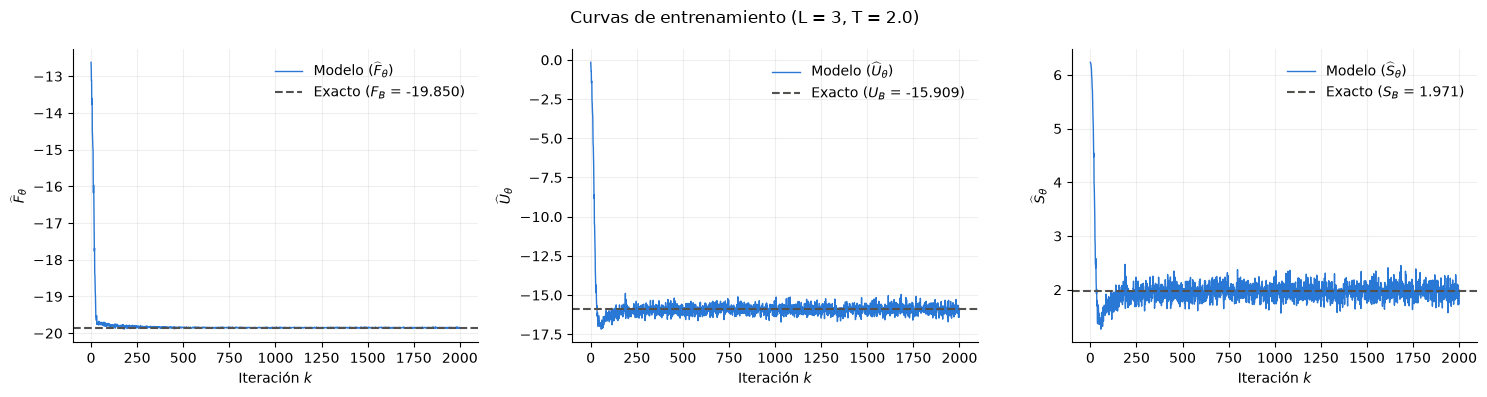

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#52514e"

# Figura 1: curvas de entrenamiento 

iteraciones = np.arange(len(historial_F))
datos = [
    (historial_F, F_B.item(), r"$\widehat{F}_\theta$", r"$F_B$"),
    (historial_U, U_B.item(), r"$\widehat{U}_\theta$", r"$U_B$"),
    (historial_S, S_B.item(), r"$\widehat{S}_\theta$", r"$S_B$"),
]
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (hist, exacto, nombre, nombre_exacto) in zip(ejes, datos):
    ax.plot(iteraciones, hist, color=AZUL, linewidth=1, label=f"Modelo ({nombre})")
    ax.axhline(exacto, color=GRIS, linestyle="--", linewidth=1.5,
               label=f"Exacto ({nombre_exacto} = {exacto:.3f})")
    ax.set_xlabel("Iteración $k$")
    ax.set_ylabel(nombre)
    ax.legend(frameon=False)
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Curvas de entrenamiento (L = {L}, T = {T})")
fig.tight_layout()
plt.show()



**Figura 1. Curvas de entrenamiento.** Evolución de la energía libre $\widehat{F}_\theta$, la energía media $\widehat{U}_\theta$ y la entropía $\widehat{S}_\theta$ estimadas con el lote ($M = 256$) en cada una de las $K = 2000$ iteraciones, para una red $3\times3$ a $T = 2$. 

 En las primeras ~100 iteraciones las tres cantidades se aproximan rápidamente a sus valores exactos. También se observa que alrededor de $k \approx 50$, $\widehat{U}_\theta$ y $\widehat{S}_\theta$ caen por debajo del valor exacto. Esto podría deberse a que el modelo estima configuraciones ordenadas antes de corregirse al tratar de minimizar la energía.

 Por otro lado, $\widehat{F}_\theta$ se estabiliza en el valor computado $F_B = -19.850$ con fluctuaciones muy pequeñas, mientras que $\widehat{U}_\theta$ y $\widehat{S}_\theta$ fluctúan notoriamente alrededor de sus valores exactos. Esto podría deberse a que, cuando el modelo se aproxima a la distribución de Boltzmann, $f_m = E_m + T\ell_m \approx F_B$ para todas las configuraciones, de modo que la varianza de $\widehat{F}_\theta$ es mucho menor que la de $\widehat{U}_\theta$ o $\widehat{S}_\theta$.

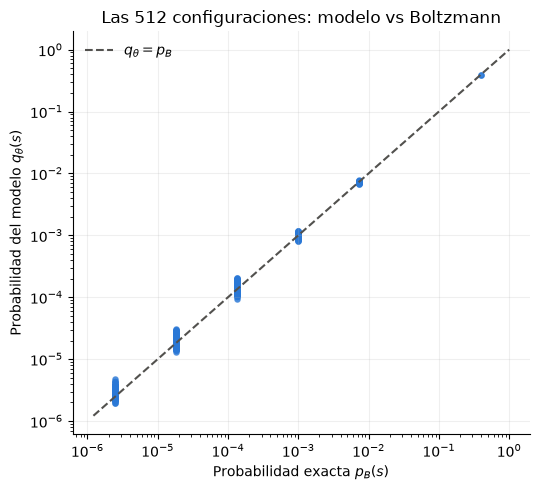

In [ ]:
# Figura 2: modelo vs Boltzmann para las 512 configuraciones 

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(p_B.cpu().numpy(), q_todas.cpu().numpy(), s=14, color=AZUL, alpha=0.7)
lim = [p_B.min().item() / 2, 1]
ax.plot(lim, lim, color=GRIS, linestyle="--", linewidth=1.5, label=r"$q_\theta = p_B$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"Probabilidad exacta $p_B(s)$")
ax.set_ylabel(r"Probabilidad del modelo $q_\theta(s)$")
ax.set_title("Las 512 configuraciones: modelo vs Boltzmann")
ax.legend(frameon=False)
ax.grid(alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()



In [45]:
# Niveles de energía distintos en la red 3x3 y cuántas configuraciones tiene cada uno
energias, cuantas = torch.unique(E_todas, return_counts=True)

print(f"{'Energía':>8s}{'Configuraciones':>18s}")
for E_val, n in zip(energias, cuantas):
    print(f"{E_val.item():8.0f}{n.item():18d}")
print(f"{'Total':>8s}{cuantas.sum().item():18d}")

 Energía   Configuraciones
     -18                 2
     -10                18
      -6                48
      -2               198
       2               144
       6               102
   Total               512


**Figura 2. Comparación entre el modelo y la distribución de Boltzmann.** 

Se compara la probabilidad asignada por el Transformer, $q_\theta(s)$, en relación a la probabilidad exacta de Boltzmann, $p_B(s)$, para cada una de las 512 configuraciones de la red $3\times3$ a $T = 2$, en escala logarítmica. Cada punto corresponde a una configuración, y la línea punteada indica el acuerdo perfecto, $q_\theta = p_B$.

Se observa que los puntos se agrupan en seis columnas porque en este caso de una red 3x3 solo existen seis valores posibles de la energía, y todas las configuraciones con la misma energía tienen la misma probabilidad de Boltzmann:

| $E$ | Configuraciones | $p_B(s)$ |
|---|---|---|
| $-18$ | 2 | $0.396$ |
| $-10$ | 18 | $7.3 \times 10^{-3}$ |
| $-6$ | 48 | $9.8 \times 10^{-4}$ |
| $-2$ | 198 | $1.3 \times 10^{-4}$ |
| $+2$ | 144 | $1.8 \times 10^{-5}$ |
| $+6$ | 102 | $2.4 \times 10^{-6}$ |

 La dispersión vertical dentro de cada columna refleja que el modelo asigna probabilidades ligeramente distintas a configuraciones que, según la distribución de Boltzmann, deberían ser igual de probables. Esta dispersión es mínima para los estados ordenados y crece hacia las configuraciones menos probables, que el modelo rara vez genera durante el entrenamiento y, por tanto, podría decirse que aprende con menor precisión.

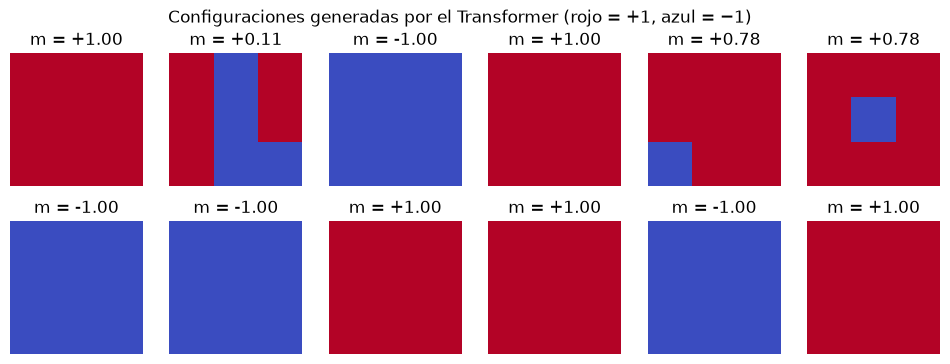

In [44]:
# Figura 3: ejemplos de configuraciones generadas
plt.figure(figsize=(12, 4))

for i in range(12):                                 # 12 configuraciones del lote
    red = s_eval[i].reshape(L, L)                    # vector de 9 espines → red 3×3
    plt.subplot(2, 6, i + 1)                         # cuadrícula de 2 filas × 6 columnas
    plt.imshow(red, cmap="coolwarm", vmin=-1, vmax=1)     # rojo = +1, azul = −1
    plt.title(f"m = {red.float().mean():+.2f}")      # magnetización de esa red
    plt.axis("off")                                  # sin ejes ni números

plt.suptitle("Configuraciones generadas por el Transformer (rojo = +1, azul = −1)")
plt.show()

**Figura 3. Ejemplos de configuraciones generadas por el Transformer entrenado.** 

Se muestran 12 configuraciones tomadas del lote de evaluación.

La mayoría de las configuraciones (9 de 12) están completamente ordenadas ($|m| = 1$), con todos los espines alineados, y aparecen ambas orientaciones: 5 con todos los espines en $+1$ y 4 con todos en $-1$. Esto indica que el modelo aprendió los dos posibles estados de orden. Las demás configuraciones presentan fluctuaciones térmicas, donde dos de ellas tienen un único espín volteado ($m = 0.78$) y una presenta un dominio más extenso de espines opuestos ($m = 0.11$). Estas proporciones son consistentes con la distribución de Boltzmann a $T = 2$, según la cual los dos estados ordenados concentran cerca del 79 % de la probabilidad y las configuraciones con un espín volteado cerca del 13 %.